# 3.4. Comparação dos domínios e interpretação dos sinais

Este notebook compara explicitamente os mesmos registros nos domínios do tempo e da frequência:

- **F0 / SV0 / SP1 / C1 / R1**: saudável;
- **F1 / SV3 / SP1 / C1**: falha de severidade máxima disponível.

A escolha de SV3 segue os notebooks existentes e o CSV `features_dom_frequencia.csv`. Para reduzir ambiguidades, o registro F1 não possui identificação de repetição no nome do arquivo. O código abaixo usa somente os metadados efetivamente presentes.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110})

DATA_DIR = Path("../../data/DronePropB Ground Testing Dataset")
F0_FILE = DATA_DIR / "F0_SV0_SP1_C1_R1.mat"
F1_FILE = DATA_DIR / "F1_SV3_SP1_C1.mat"

def load_record(path):
    acc = loadmat(path, simplify_cells=True)["AccData"]
    signal = np.asarray(acc["Vib_Data"], dtype=float).squeeze()
    timestamps = np.asarray(acc["t"], dtype=float).squeeze()
    fs = float(acc["samplingRate"])
    return signal, timestamps, fs

f0, t0, fs0 = load_record(F0_FILE)
f1, t1, fs1 = load_record(F1_FILE)

print("F0:", F0_FILE.name, len(f0), "amostras", fs0, "Hz")
print("F1:", F1_FILE.name, len(f1), "amostras", fs1, "Hz")


F0: F0_SV0_SP1_C1_R1.mat 600000 amostras 10000.0 Hz
F1: F1_SV3_SP1_C1.mat 600000 amostras 10000.0 Hz


## 1. Comparação direta no mesmo intervalo inicial

Os dois sinais são exibidos no tempo e na frequência usando as primeiras 0,2 s. Este intervalo contém aproximadamente 2.000 amostras e fornece resolução espectral de cerca de 5 Hz.


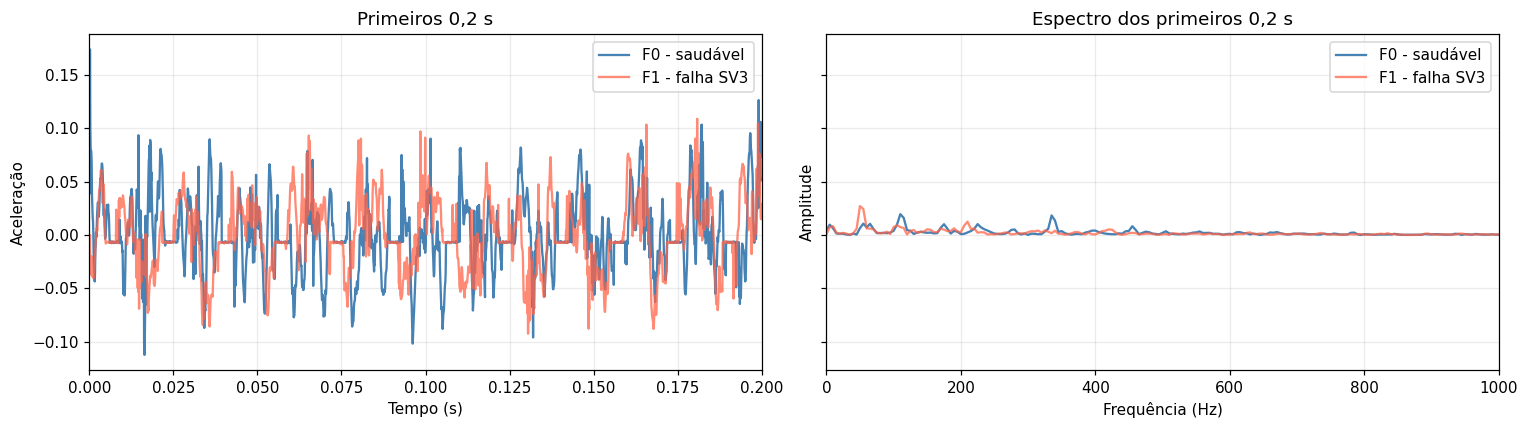

In [2]:
N_show = int(round(min(fs0, fs1) * 0.2))
x0 = f0[:N_show]
x1 = f1[:N_show]
freq_time = np.arange(N_show) / fs0

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
axes[0].plot(freq_time, x0, color="steelblue", label="F0 - saudável")
axes[0].plot(freq_time, x1, color="tomato", alpha=0.75, label="F1 - falha SV3")
axes[0].set(title="Primeiros 0,2 s", xlabel="Tempo (s)", ylabel="Aceleração", xlim=(0, 0.2))
axes[0].legend(); axes[0].grid(alpha=.25)

def fft_feature(signal, fs=10000):
    signal = np.asarray(signal, dtype=float).squeeze()
    n = len(signal)
    centered = signal - np.mean(signal)
    window = np.hanning(n)
    fft = np.fft.rfft(centered * window)
    freqs = np.fft.rfftfreq(n, d=1/fs)
    amplitude = np.abs(fft) / np.sum(window)
    if n % 2 == 0:
        amplitude[1:-1] *= 2
    else:
        amplitude[1:] *= 2
    return freqs, amplitude

freq0, amp0 = fft_feature(x0, fs0)
freq1, amp1 = fft_feature(x1, fs1)
axes[1].plot(freq0, amp0, color="steelblue", label="F0 - saudável")
axes[1].plot(freq1, amp1, color="tomato", alpha=0.75, label="F1 - falha SV3")
axes[1].set(title="Espectro dos primeiros 0,2 s", xlabel="Frequência (Hz)", ylabel="Amplitude")
axes[1].set_xlim(0, 1000)
axes[1].legend(); axes[1].grid(alpha=.25)
plt.tight_layout()
plt.show()


In [3]:
def spectral_metrics(signal, fs=10000):
    freqs, amp = fft_feature(signal, fs)

    positive = np.arange(1, len(freqs))
    kdom = positive[np.argmax(amp[positive])]
    freq_dom = freqs[kdom]
    mag_dom = amp[kdom]

    amp_no_dc = amp.copy()
    amp_no_dc[0] = 0
    centroid = np.sum(freqs * amp_no_dc) / np.sum(amp_no_dc)

    probability = amp_no_dc[positive] ** 2
    probability = probability / np.sum(probability)
    probability = probability[probability > 0]
    entropy = -np.sum(probability * np.log2(probability))

    return freqs, amp, freq_dom, mag_dom, centroid, entropy

_, _, fd0, mp0, c0, h0 = spectral_metrics(x0, fs0)
_, _, fd1, mp1, c1, h1 = spectral_metrics(x1, fs1)

print(f"F0: frequência dominante={fd0:.2f} Hz, magnitude={mp0:.5f}, centroide={c0:.2f} Hz, entropia={h0:.2f} bits")
print(f"F1: frequência dominante={fd1:.2f} Hz, magnitude={mp1:.5f}, centroide={c1:.2f} Hz, entropia={h1:.2f} bits")


F0: frequência dominante=110.00 Hz, magnitude=0.01951, centroide=1464.21 Hz, entropia=5.79 bits
F1: frequência dominante=50.00 Hz, magnitude=0.02709, centroide=1537.80 Hz, entropia=5.30 bits


### Achados deste trecho

Os gráficos não são uma comparação de dois números isolados: ambos usam o mesmo intervalo temporal e o mesmo procedimento de FFT. As diferenças observadas são comparadas novamente nas janelas completas na seção seguinte.


## 2. Extração temporal e espectral das mesmas 300 janelas

Cada registro é dividido em 300 segmentos consecutivos de 0,2 s, sem sobreposição. Para cada segmento são extraídas características dos dois domínios.


In [4]:
FS = 10000
WINDOW_S = 0.2
N_WINDOW = int(round(FS * WINDOW_S))

def time_features(signal):
    signal = np.asarray(signal, dtype=float).squeeze()
    mean = np.mean(signal)
    rms = np.sqrt(np.mean(signal ** 2))
    std = np.std(signal)
    peak = np.max(np.abs(signal))
    pp = np.ptp(signal)
    crest = peak / rms if rms > 0 else np.nan
    duration = len(signal) / FS
    trapz = getattr(np, "trapezoid", np.trapz)
    power = trapz(signal ** 2, dx=1/FS) / duration
    return mean, rms, std, peak, pp, crest, power

bands = [(0, 500), (500, 2000), (2000, 5000)]

def window_features(signal, condition, source_file):
    rows = []
    signal = np.asarray(signal, dtype=float).squeeze()

    freqs_full, amp_full = fft_feature(signal[:N_WINDOW], FS)

    for window_index, start in enumerate(range(0, len(signal) - N_WINDOW + 1, N_WINDOW)):
        segment = signal[start:start + N_WINDOW]
        mean, rms, std, peak, pp, crest, power = time_features(segment)

        freqs, amp, freq_dom, mag_dom, centroid, entropy = spectral_metrics(segment, FS)

        window = np.hanning(len(segment))
        centered = segment - np.mean(segment)
        fft = np.fft.rfft(centered * window)
        psd = np.abs(fft) ** 2
        psd = psd / (FS * np.sum(window ** 2))
        if len(segment) % 2 == 0:
            psd[1:-1] *= 2
        else:
            psd[1:] *= 2

        band_powers = {}
        df = freqs[1] - freqs[0]
        for i, (low, high) in enumerate(bands):
            mask = (freqs >= low) & (freqs <= high)
            band_powers[f"P_{low}_{high}"] = np.sum(psd[mask] * df)

        rows.append({
            "Condicao": condition,
            "Arquivo": source_file,
            "Janela": window_index,
            "Tempo_inicio_s": start / FS,
            "Media": mean,
            "RMS": rms,
            "Desvio_padrao": std,
            "Pico_absoluto": peak,
            "Pico_a_pico": pp,
            "Fator_de_crista": crest,
            "Potencia_media": power,
            "Freq_dominante_Hz": freq_dom,
            "Magnitude_pico": mag_dom,
            "Centroide_Hz": centroid,
            "Entropia_bits": entropy,
            **band_powers,
        })
    return pd.DataFrame(rows)

df0 = window_features(f0, "F0 - saudável", F0_FILE.name)
df1 = window_features(f1, "F1 - falha SV3", F1_FILE.name)
df_windows = pd.concat([df0, df1], ignore_index=True)

print("Linhas por condição:")
print(df_windows.groupby("Condicao").size())
df_windows.head()


Linhas por condição:
Condicao
F0 - saudável     300
F1 - falha SV3    300
dtype: int64


,Condicao,Arquivo,Janela,Tempo_inicio_s,Media,RMS,Desvio_padrao,Pico_absoluto,Pico_a_pico,Fator_de_crista,Potencia_media,Freq_dominante_Hz,Magnitude_pico,Centroide_Hz,Entropia_bits,P_0_500,P_500_2000,P_2000_5000
0,F0 - saudável,F0_SV0_SP1_C1_R1.mat,0,0.0,-0.000108,0.033662,0.033662,0.173737,0.285984,5.161190,0.001131,110.0,0.019511,1464.205122,5.785920,0.000906,0.000077,0.000047
1,F0 - saudável,F0_SV0_SP1_C1_R1.mat,1,0.2,-0.004068,0.045300,0.045117,0.181344,0.321492,4.003179,0.002051,55.0,0.034700,1502.388104,4.682168,0.001922,0.000100,0.000068
2,F0 - saudável,F0_SV0_SP1_C1_R1.mat,2,0.4,0.001689,0.057965,0.057940,0.237005,0.471842,4.088775,0.003360,55.0,0.045655,1480.060844,4.647594,0.003674,0.000172,0.000148
3,F0 - saudável,F0_SV0_SP1_C1_R1.mat,3,0.6,-0.000631,0.055457,0.055454,0.188062,0.339726,3.391100,0.003072,55.0,0.040311,1540.326052,4.850158,0.001997,0.000120,0.000104
4,F0 - saudável,F0_SV0_SP1_C1_R1.mat,4,0.8,-0.000492,0.053359,0.053357,0.195809,0.346444,3.669646,0.002844,55.0,0.049031,1502.132967,4.639321,0.002270,0.000102,0.000101


In [5]:
numeric_features = [
    "RMS", "Pico_absoluto", "Pico_a_pico", "Fator_de_crista", "Potencia_media",
    "Freq_dominante_Hz", "Magnitude_pico", "P_0_500", "P_500_2000",
    "P_2000_5000", "Centroide_Hz", "Entropia_bits",
]

summary = df_windows.groupby("Condicao")[numeric_features].agg(["mean", "std"])
summary.round(6)


RMS           Pico_absoluto           Pico_a_pico  \
                    mean       std          mean       std        mean   
Condicao                                                                 
F0 - saudável   0.043424  0.009546      0.164152  0.031586    0.293084   
F1 - falha SV3  0.031153  0.002580      0.126066  0.018275    0.220888   

                         Fator_de_crista           Potencia_media            \
                     std            mean       std           mean       std   
Condicao                                                                      
F0 - saudável   0.051592        3.854867  0.632681       0.001976  0.000844   
F1 - falha SV3  0.023001        4.057896  0.574746       0.000977  0.000161   

                ...   P_0_500           P_500_2000           P_2000_5000  \
                ...      mean       std       mean       std        mean   
Condicao        ...                                                        
F0 - saudável   ...  0.001759  0.000836   0.000128  0.000033    0.000078   
F1 - falha SV3  ...  0.000862  0.000170   0.000073  0.000012    0.000047   

                         Centroide_Hz            Entropia_bits            
                     std         mean        std          mean       std  
Condicao                                                                  
F0 - saudável   0.000031  1497.298142  82.427592      5.019081  0.594079  
F1 - falha SV3  0.000010  1519.688281  65.313748      5.184715  0.284423  

[2 rows x 24 columns]

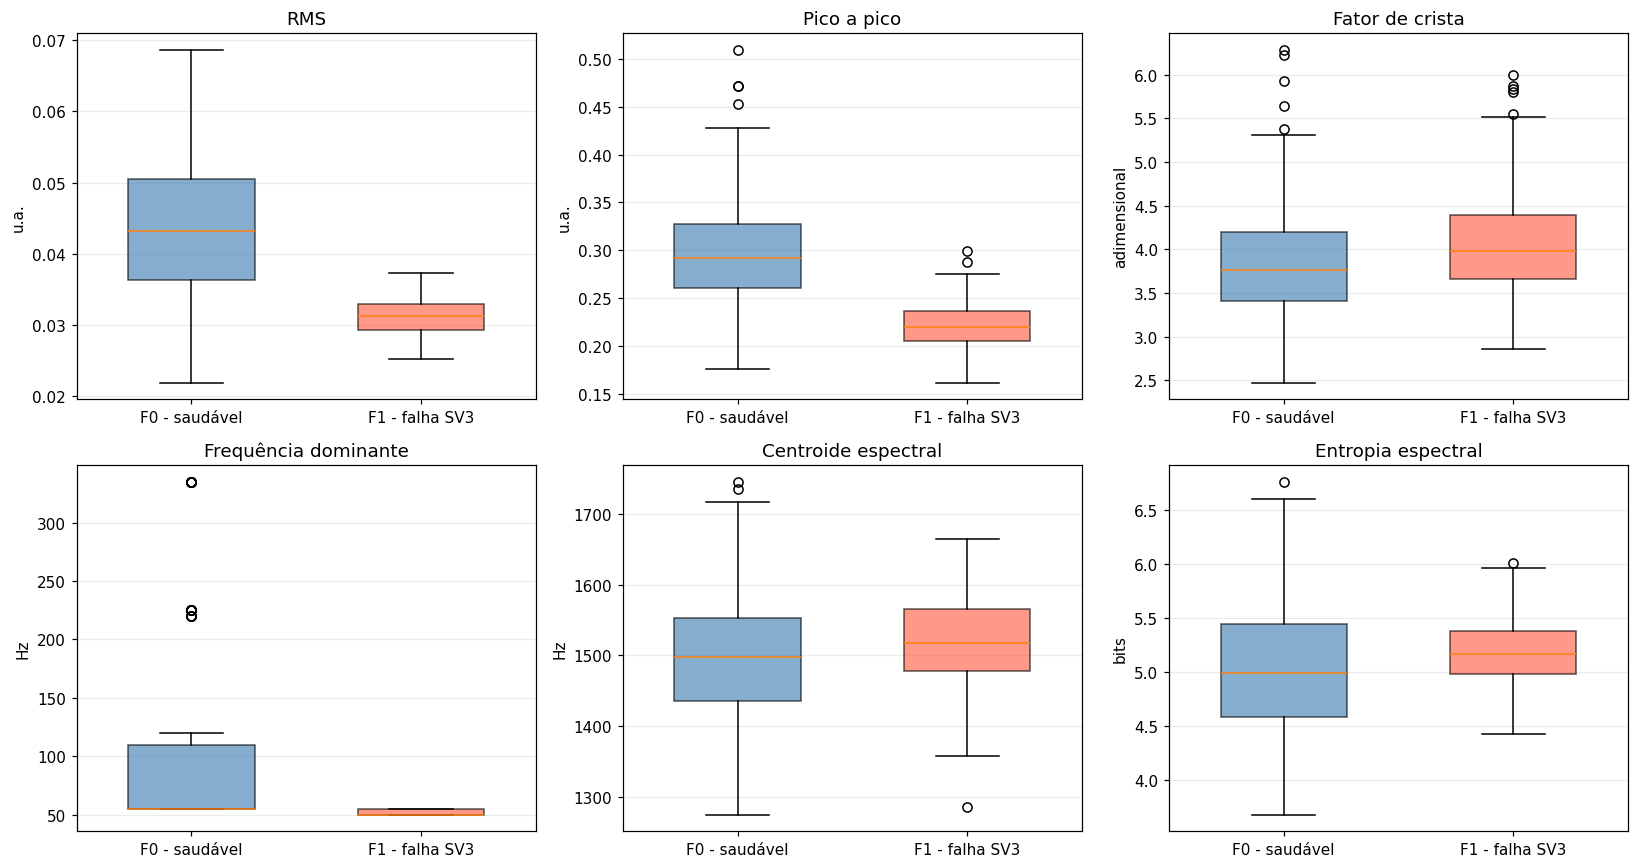

In [6]:
plot_features = [
    ("RMS", "RMS", "u.a."),
    ("Pico_a_pico", "Pico a pico", "u.a."),
    ("Fator_de_crista", "Fator de crista", "adimensional"),
    ("Freq_dominante_Hz", "Frequência dominante", "Hz"),
    ("Centroide_Hz", "Centroide espectral", "Hz"),
    ("Entropia_bits", "Entropia espectral", "bits"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
colors = {"F0 - saudável": "steelblue", "F1 - falha SV3": "tomato"}
for ax, (column, title, unit) in zip(axes.ravel(), plot_features):
    data = [df_windows.loc[df_windows["Condicao"] == c, column].dropna() for c in colors]
    bp = ax.boxplot(data, tick_labels=list(colors), widths=0.55, patch_artist=True)
    for patch, color in zip(bp["boxes"], colors.values()):
        patch.set_facecolor(color)
        patch.set_alpha(0.65)
    ax.set_title(title)
    ax.set_ylabel(unit)
    ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


## 3. Quais características separam melhor as condições?

Para comparar os domínios em escala comum, calcula-se o tamanho de efeito *d* de Cohen a partir das médias das 300 janelas:

$$
d = \frac{\bar{x}_{F1}-\bar{x}_{F0}}{s_p},
$$

em que $s_p$ é o desvio padrão combinado:

$$
s_p = \sqrt{\frac{(n_{F0}-1)s_{F0}^{2}+(n_{F1}-1)s_{F1}^{2}}{n_{F0}+n_{F1}-2}}.
$$

Valores absolutos maiores indicam separação mais clara entre os grupos.


In [7]:
def cohens_d(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    na, nb = len(a), len(b)
    pooled = np.sqrt(((na - 1)*np.var(a, ddof=1) + (nb - 1)*np.var(b, ddof=1)) / (na + nb - 2))
    return (np.mean(b) - np.mean(a)) / pooled if pooled > 0 else 0.0

f0mask = df_windows["Condicao"] == "F0 - saudável"
f1mask = df_windows["Condicao"] == "F1 - falha SV3"

effect_rows = []
for col in numeric_features:
    d = cohens_d(df_windows.loc[f0mask, col], df_windows.loc[f1mask, col])
    effect_rows.append({"Caracteristica": col, "d_Cohen_F1_menos_F0": d,
                        "abs_d": abs(d)})
effects = pd.DataFrame(effect_rows).sort_values("abs_d", ascending=False)
effects.round(3)


,Caracteristica,d_Cohen_F1_menos_F0,abs_d
8,P_500_2000,-2.173,2.173
2,Pico_a_pico,-1.808,1.808
0,RMS,-1.755,1.755
4,Potencia_media,-1.645,1.645
7,P_0_500,-1.488,1.488
1,Pico_absoluto,-1.476,1.476
9,P_2000_5000,-1.316,1.316
6,Magnitude_pico,-1.110,1.110
5,Freq_dominante_Hz,-0.705,0.705
11,Entropia_bits,0.356,0.356


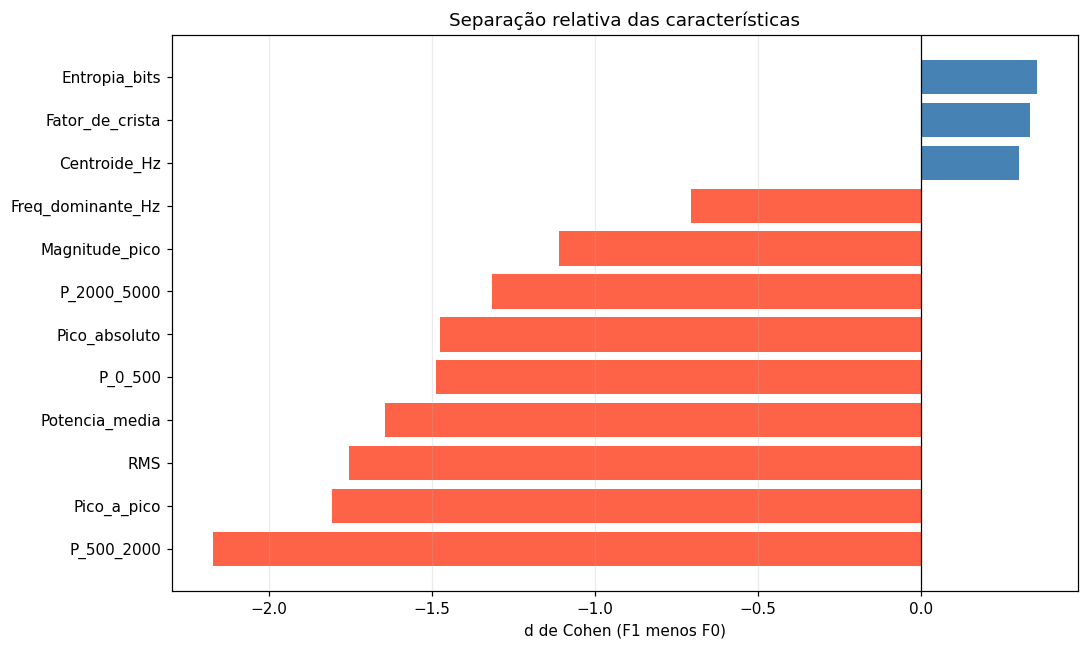

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
ordered = effects.sort_values("d_Cohen_F1_menos_F0")
colors = ["tomato" if d < 0 else "steelblue" for d in ordered["d_Cohen_F1_menos_F0"]]
ax.barh(ordered["Caracteristica"], ordered["d_Cohen_F1_menos_F0"], color=colors)
ax.axvline(0, color="black", lw=.8)
ax.set_xlabel("d de Cohen (F1 menos F0)")
ax.set_title("Separação relativa das características")
ax.grid(axis="x", alpha=.25)
plt.tight_layout()
plt.show()


## 4. Investigação de redundância

A redundância é avaliada pela correlação de Pearson entre características das 600 janelas. Correlação absoluta alta indica que duas medidas carregam informação muito semelhante nesta amostra.


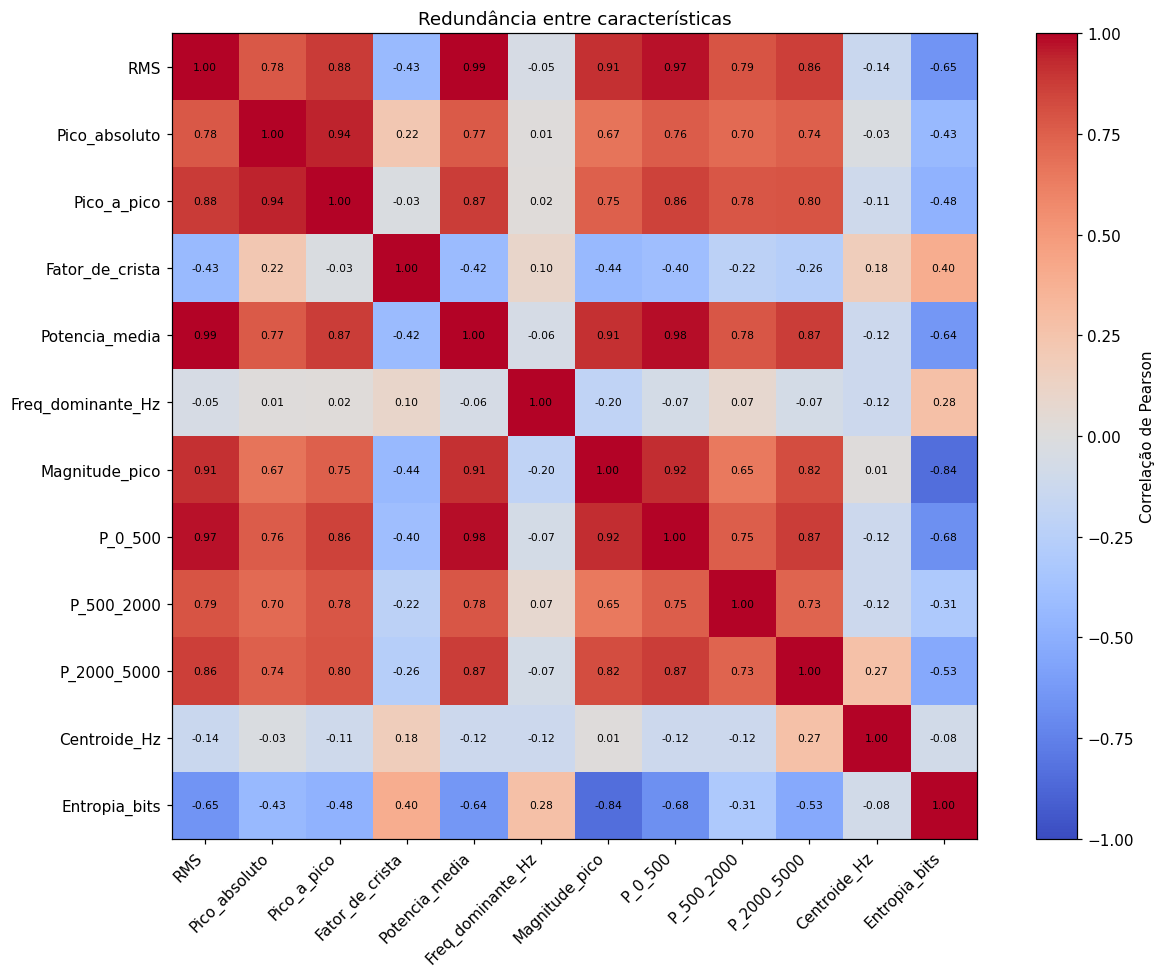

In [9]:
correlation = df_windows[numeric_features].corr(method="pearson")

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_features)), numeric_features, rotation=45, ha="right")
ax.set_yticks(range(len(numeric_features)), numeric_features)
for i in range(len(numeric_features)):
    for j in range(len(numeric_features)):
        ax.text(j, i, f"{correlation.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="Correlação de Pearson")
ax.set_title("Redundância entre características")
plt.tight_layout()
plt.show()


In [10]:
pairs = []
for i, col1 in enumerate(numeric_features):
    for col2 in numeric_features[i+1:]:
        pairs.append((col1, col2, correlation.loc[col1, col2]))

redundant = pd.DataFrame(pairs, columns=["Caracteristica_1", "Caracteristica_2", "Correlacao"])
redundant["abs_correlacao"] = redundant["Correlacao"].abs()
redundant.sort_values("abs_correlacao", ascending=False).head(15).round(3)


,Caracteristica_1,Caracteristica_2,Correlacao,abs_correlacao
3,RMS,Potencia_media,0.993,0.993
40,Potencia_media,P_0_500,0.978,0.978
6,RMS,P_0_500,0.971,0.971
11,Pico_absoluto,Pico_a_pico,0.939,0.939
51,Magnitude_pico,P_0_500,0.918,0.918
5,RMS,Magnitude_pico,0.913,0.913
39,Potencia_media,Magnitude_pico,0.910,0.910
1,RMS,Pico_a_pico,0.880,0.880
22,Pico_a_pico,Potencia_media,0.870,0.870
57,P_0_500,P_2000_5000,0.870,0.870


## 5. Conjunto recomendado para classificação

A seleção deve evitar manter simultaneamente variáveis que medem quase a mesma propriedade. A recomendação abaixo combina:

1. uma medida temporal com bom efeito e baixa redundância;
2. frequência dominante ou centroide para representar a distribuição espectral;
3. entropia para representar concentração/distribuição do espectro;
4. uma característica não redundante de energia ou banda, apenas se houver ganho real.

A escolha deve ser confirmada por validação cruzada por aquisição, pois janelas da mesma aquisição não são amostras independentes.


In [11]:
print("As cinco maiores separações absolutas:")
print(effects.head(5).round(3).to_string(index=False))

print("\nPares com |correlação| >= 0.90:")
print(redundant.loc[redundant["abs_correlacao"] >= 0.90,
                   ["Caracteristica_1", "Caracteristica_2", "Correlacao"]].sort_values("Correlacao", key=abs, ascending=False).round(3).to_string(index=False))

print("\nConjunto inicial recomendado: RMS, Fator_de_crista, Freq_dominante_Hz, Entropia_bits")

As cinco maiores separações absolutas:
Caracteristica  d_Cohen_F1_menos_F0  abs_d
    P_500_2000               -2.173  2.173
   Pico_a_pico               -1.808  1.808
           RMS               -1.755  1.755
Potencia_media               -1.645  1.645
       P_0_500               -1.488  1.488

Pares com |correlação| >= 0.90:
Caracteristica_1 Caracteristica_2  Correlacao
             RMS   Potencia_media       0.993
  Potencia_media          P_0_500       0.978
             RMS          P_0_500       0.971
   Pico_absoluto      Pico_a_pico       0.939
  Magnitude_pico          P_0_500       0.918
             RMS   Magnitude_pico       0.913
  Potencia_media   Magnitude_pico       0.910

Conjunto inicial recomendado: RMS, Fator_de_crista, Freq_dominante_Hz, Entropia_bits


In [12]:
features_recommended = [
    "RMS", "Fator_de_crista", "Freq_dominante_Hz", "Entropia_bits"
]
print("Médias de F0 e F1 para o conjunto recomendado:")
print(df_windows.groupby("Condicao")[features_recommended].mean().round(6))

print("\nConjunto completo após remoção inicial de redundâncias:")
print("- RMS: representa a amplitude média da vibração;")
print("- Fator de crista: representa a ocorrência relativa de picos;")
print("- Frequência dominante: representa o principal componente observado;")
print("- Entropia espectral: representa a distribuição/concentração espectral;")


Médias de F0 e F1 para o conjunto recomendado:
                     RMS  Fator_de_crista  Freq_dominante_Hz  Entropia_bits
Condicao                                                                   
F0 - saudável   0.043424         3.854867          81.883333       5.019081
F1 - falha SV3  0.031153         4.057896          51.500000       5.184715

Conjunto completo após remoção inicial de redundâncias:
- RMS: representa a amplitude média da vibração;
- Fator de crista: representa a ocorrência relativa de picos;
- Frequência dominante: representa o principal componente observado;
- Entropia espectral: representa a distribuição/concentração espectral;


## Conclusões

1. O domínio do tempo permite observar diferenças de amplitude, como RMS e picos, mas não explica diretamente a redistribuição das componentes de frequência.
2. O domínio da frequência permite observar deslocamentos da frequência dominante, concentração espectral e centroide. A entropia e o centroide podem ser úteis mesmo quando a potência total é semelhante.
3. RMS, desvio padrão e potência média são medidas relacionadas e tendem a carregar redundância. Pico absoluto e pico a pico também podem ser próximos, assim como bandas próximas.
4. Portanto, não se presume que características espectrais sejam automaticamente superiores. O conjunto recomendado combina uma medida temporal robusta, uma medida temporal de picos e duas características espectrais complementares.
5. Esta recomendação é exploratória: a efetividade final deve ser medida por classificação separada por aquisição, evitando misturar janelas do mesmo arquivo entre treino e teste.
